In [32]:
# ============================================================
# BLOCO: baixar o dataset direto do Kaggle (sem fazer upload)
# ============================================================
!pip install -q kagglehub

import os
import kagglehub

# Baixa o dataset direto do Kaggle
path = kagglehub.dataset_download("abdullahkhanuet22/road-classification")
print("Baixado em:", path)

# Mostra a estrutura de pastas e a quantidade de imagens
IMG_EXT = (".jpg", ".jpeg", ".png")
for root, dirs, files in os.walk(path):
    n = sum(f.lower().endswith(IMG_EXT) for f in files)
    print(root, "| subpastas:", dirs, "| imagens:", n)

# Localiza a pasta que contém as subpastas de classe
def find_data_dir(root):
    for r, dirs, files in os.walk(root):
        class_dirs = [d for d in dirs
                      if any(f.lower().endswith(IMG_EXT)
                             for f in os.listdir(os.path.join(r, d)))]
        if len(class_dirs) >= 2:
            return r

DATA_DIR = find_data_dir(path)
print("DATA_DIR:", DATA_DIR)

Using Colab cache for faster access to the 'road-classification' dataset.
Baixado em: /kaggle/input/road-classification
/kaggle/input/road-classification | subpastas: ['Road Classification'] | imagens: 0
/kaggle/input/road-classification/Road Classification | subpastas: ['Broken', 'Not Broken'] | imagens: 0
/kaggle/input/road-classification/Road Classification/Broken | subpastas: [] | imagens: 110
/kaggle/input/road-classification/Road Classification/Not Broken | subpastas: [] | imagens: 94
DATA_DIR: /kaggle/input/road-classification/Road Classification


In [33]:
# ============================================================
# BLOCO 2: importar as bibliotecas
# ============================================================

import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow.keras import layers, models
from tensorflow.keras.applications import EfficientNetB0
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau
from sklearn.model_selection import StratifiedKFold, train_test_split
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, roc_auc_score, confusion_matrix,
                             ConfusionMatrixDisplay)

# Sementes fixas para reprodutibilidade
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)

In [34]:
IMG_SIZE = 224
BATCH_SIZE = 16
N_FOLDS = 5

EPOCHS_HEAD = 15     # fase 1: treina só o classificador final
EPOCHS_FT = 15       # fase 2: fine-tuning das últimas camadas
LR_HEAD = 1e-3
LR_FT = 1e-5
N_UNFREEZE = 20

In [35]:
# Ordena as classes para que "Not Broken" = 0 e "Broken" = 1
# (assim a classe 1 é a rua quebrada, e precisão/recall/SHAP se referem a ela)
class_names = sorted([d for d in os.listdir(DATA_DIR)
                     if os.path.isdir(os.path.join(DATA_DIR, d))],
                     key=lambda n: ("not" not in n.lower(), n))
print("Classes (índice -> nome):", dict(enumerate(class_names)))

paths, labels = [], []
for idx, cname in enumerate(class_names):
    folder = os.path.join(DATA_DIR, cname)
    for f in os.listdir(folder):
        if f.lower().endswith(IMG_EXT):
            paths.append(os.path.join(folder, f))
            labels.append(idx)

paths = np.array(paths)
labels = np.array(labels)
print("Total de imagens:", len(paths))
print("Imagens por classe:", np.bincount(labels))

Classes (índice -> nome): {0: 'Not Broken', 1: 'Broken'}
Total de imagens: 204
Imagens por classe: [ 94 110]


In [36]:
def load_image(path, label):
    img = tf.io.read_file(path)
    img = tf.io.decode_image(img, channels=3, expand_animations=False)
    img = tf.image.resize(img, (IMG_SIZE, IMG_SIZE))
    return img, tf.cast(label, tf.float32)

def make_ds(p, y, training):
    ds = tf.data.Dataset.from_tensor_slices((p, y))
    if training:
        ds = ds.shuffle(len(p), seed=SEED)   # embaralha só no treino
    ds = ds.map(load_image, num_parallel_calls=tf.data.AUTOTUNE)
    return ds.batch(BATCH_SIZE).prefetch(tf.data.AUTOTUNE)

In [37]:
data_augmentation = tf.keras.Sequential([
    layers.RandomFlip("horizontal"),
    layers.RandomRotation(0.08),
    layers.RandomZoom(0.1),
    layers.RandomContrast(0.3),
    layers.RandomBrightness(0.3, value_range=(0, 255)),
], name="aumento_de_dados")

In [38]:
def build_model():
    base = EfficientNetB0(include_top=False, weights="imagenet",
                          input_shape=(IMG_SIZE, IMG_SIZE, 3))
    base.trainable = False   # fase 1: base congelada

    inputs = layers.Input(shape=(IMG_SIZE, IMG_SIZE, 3))
    x = data_augmentation(inputs)
    x = base(x, training=False)          # mantém BatchNorm em modo de inferência
    x = layers.GlobalAveragePooling2D()(x)
    x = layers.Dropout(0.4)(x)
    outputs = layers.Dense(1, activation="sigmoid")(x)
    return models.Model(inputs, outputs), base

In [39]:
def compile_model(model, lr):
    model.compile(optimizer=tf.keras.optimizers.Adam(lr),
                  loss="binary_crossentropy",
                  metrics=["accuracy"])

def get_callbacks():
    return [
        EarlyStopping(monitor="val_loss", patience=5, restore_best_weights=True),
        ReduceLROnPlateau(monitor="val_loss", factor=0.3, patience=2, min_lr=1e-7),
    ]

In [40]:
skf = StratifiedKFold(n_splits=N_FOLDS, shuffle=True, random_state=SEED)

results = []
cm_total = np.zeros((2, 2), dtype=int)
histories = []

for fold, (tr_idx, te_idx) in enumerate(skf.split(paths, labels), start=1):
    print(f"\n===== FOLD {fold}/{N_FOLDS} =====")
    tf.keras.backend.clear_session()

    # Divisão: teste (fold) | treino e validação (resto)
    p_trval, y_trval = paths[tr_idx], labels[tr_idx]
    p_te, y_te = paths[te_idx], labels[te_idx]
    p_tr, p_val, y_tr, y_val = train_test_split(
        p_trval, y_trval, test_size=0.15, stratify=y_trval, random_state=SEED)

    train_ds = make_ds(p_tr, y_tr, training=True)
    val_ds = make_ds(p_val, y_val, training=False)
    test_ds = make_ds(p_te, y_te, training=False)

    model, base = build_model()

    # FASE 1: treina só a cabeça de classificação
    compile_model(model, LR_HEAD)
    h1 = model.fit(train_ds, validation_data=val_ds, epochs=EPOCHS_HEAD,
                   callbacks=get_callbacks(), verbose=0)

    # FASE 2: fine-tuning das últimas camadas da base
    base.trainable = True
    for layer in base.layers[:-N_UNFREEZE]:
        layer.trainable = False
    for layer in base.layers:
        if isinstance(layer, layers.BatchNormalization):
            layer.trainable = False
    compile_model(model, LR_FT)   # recompilar após mudar o que é treinável
    h2 = model.fit(train_ds, validation_data=val_ds, epochs=EPOCHS_FT,
                   callbacks=get_callbacks(), verbose=0)
    histories.append((h1.history, h2.history))

    # Avaliação no fold de teste
    probs = model.predict(test_ds, verbose=0).ravel()
    preds = (probs >= 0.5).astype(int)

    results.append({
        "fold": fold,
        "acuracia": accuracy_score(y_te, preds),
        "precisao": precision_score(y_te, preds, zero_division=0),
        "recall": recall_score(y_te, preds, zero_division=0),
        "f1": f1_score(y_te, preds, zero_division=0),
        "auc": roc_auc_score(y_te, probs),
    })
    cm_total += confusion_matrix(y_te, preds, labels=[0, 1])
    print({k: round(v, 3) for k, v in results[-1].items()})


===== FOLD 1/5 =====
{'fold': 1, 'acuracia': 0.902, 'precisao': 0.909, 'recall': 0.909, 'f1': 0.909, 'auc': np.float64(0.967)}

===== FOLD 2/5 =====
{'fold': 2, 'acuracia': 0.878, 'precisao': 0.84, 'recall': 0.955, 'f1': 0.894, 'auc': np.float64(0.938)}

===== FOLD 3/5 =====
{'fold': 3, 'acuracia': 0.78, 'precisao': 0.724, 'recall': 0.955, 'f1': 0.824, 'auc': np.float64(0.959)}

===== FOLD 4/5 =====
{'fold': 4, 'acuracia': 0.854, 'precisao': 0.864, 'recall': 0.864, 'f1': 0.864, 'auc': np.float64(0.945)}

===== FOLD 5/5 =====
{'fold': 5, 'acuracia': 0.85, 'precisao': 0.9, 'recall': 0.818, 'f1': 0.857, 'auc': np.float64(0.929)}


In [41]:
df = pd.DataFrame(results)
print(df.round(4).to_string(index=False))
print("\nMédia e desvio padrão:")
print(df.drop(columns="fold").agg(["mean", "std"]).round(4))

 fold  acuracia  precisao  recall     f1    auc
    1    0.9024    0.9091  0.9091 0.9091 0.9665
    2    0.8780    0.8400  0.9545 0.8936 0.9378
    3    0.7805    0.7241  0.9545 0.8235 0.9593
    4    0.8537    0.8636  0.8636 0.8636 0.9450
    5    0.8500    0.9000  0.8182 0.8571 0.9293

Média e desvio padrão:
      acuracia  precisao  recall      f1     auc
mean    0.8529    0.8474  0.9000  0.8694  0.9476
std     0.0457    0.0743  0.0593  0.0334  0.0153


In [49]:
# Diagnóstico: o modelo separa bem as duas classes no fold de teste?
probs_te = model.predict(test_ds, verbose=0).ravel()
print("Probabilidade mínima / máxima:", probs_te.min().round(3), "/", probs_te.max().round(3))
print("Média nas quebradas:    ", probs_te[y_te == 1].mean().round(3))
print("Média nas não quebradas:", probs_te[y_te == 0].mean().round(3))

Probabilidade mínima / máxima: 0.018 / 0.995
Média nas quebradas:     0.782
Média nas não quebradas: 0.209


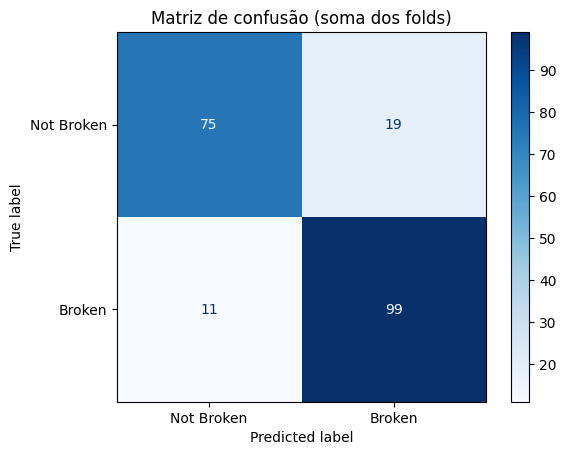

In [42]:
disp = ConfusionMatrixDisplay(cm_total, display_labels=class_names)
disp.plot(cmap="Blues", values_format="d")
plt.title("Matriz de confusão (soma dos folds)")
plt.show()

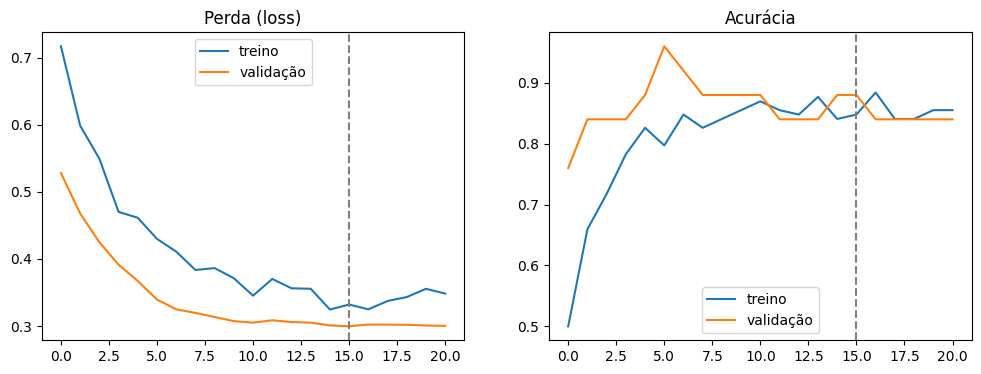

In [43]:
FOLD_PLOT = 0   # índice do fold a plotar (0 = primeiro)
h1, h2 = histories[FOLD_PLOT]

loss = h1["loss"] + h2["loss"]
val_loss = h1["val_loss"] + h2["val_loss"]
acc = h1["accuracy"] + h2["accuracy"]
val_acc = h1["val_accuracy"] + h2["val_accuracy"]
start_ft = len(h1["loss"])

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].plot(loss, label="treino")
ax[0].plot(val_loss, label="validação")
ax[0].axvline(start_ft, ls="--", c="gray")
ax[0].set_title("Perda (loss)")
ax[0].legend()

ax[1].plot(acc, label="treino")
ax[1].plot(val_acc, label="validação")
ax[1].axvline(start_ft, ls="--", c="gray")
ax[1].set_title("Acurácia")
ax[1].legend()
plt.show()

Broken: 110 imagens
Not Broken: 94 imagens


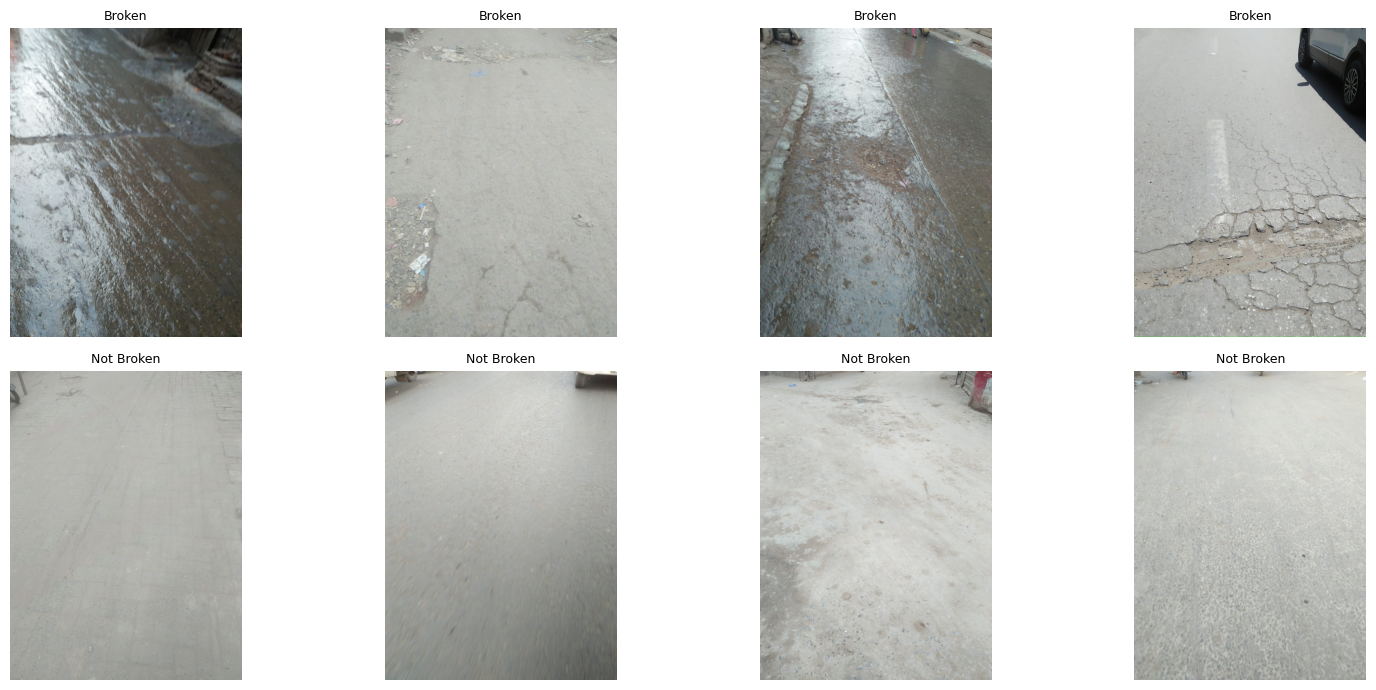

In [44]:
import os, random
import matplotlib.pyplot as plt
import matplotlib.image as mpimg

EXT = (".jpg", ".jpeg", ".png")
classes = sorted([d for d in os.listdir(DATA_DIR)
                  if os.path.isdir(os.path.join(DATA_DIR, d))])
N_SHOW = 4   # quantas imagens mostrar por classe

fig, axes = plt.subplots(len(classes), N_SHOW,
                         figsize=(4 * N_SHOW, 3.5 * len(classes)))

for i, cname in enumerate(classes):
    folder = os.path.join(DATA_DIR, cname)
    arquivos = [f for f in os.listdir(folder) if f.lower().endswith(EXT)]
    print(f"{cname}: {len(arquivos)} imagens")
    for j, f in enumerate(random.sample(arquivos, N_SHOW)):
        ax = axes[i][j]
        ax.imshow(mpimg.imread(os.path.join(folder, f)))
        ax.set_title(cname, fontsize=9)
        ax.axis("off")

plt.tight_layout()
plt.show()

In [48]:
# Instala a biblioteca SHAP (explicabilidade de modelos)
!pip install -q shap

In [ ]:
import shap

# Escolhe 2 imagens de cada classe do conjunto de teste do último fold
rng = np.random.default_rng(SEED)
sel = []
for c in [0, 1]:
    idx = np.where(y_te == c)[0]
    sel += list(rng.choice(idx, 2, replace=False))

# Carrega as imagens como array (4, 224, 224, 3), com valores de 0 a 255
X = np.stack([load_image(p_te[i], 0)[0].numpy() for i in sel])
y_true = [class_names[y_te[i]] for i in sel]

# Função que o SHAP chama para saber o que o modelo prevê
def predict_fn(imgs):
    return model.predict(imgs, verbose=0)   # probabilidade da classe 1

# O "masker" esconde partes da imagem (com desfoque) para medir o efeito de cada região
masker = shap.maskers.Image("blur(64,64)", X[0].shape)
explainer = shap.Explainer(predict_fn, masker, output_names=[class_names[1]])

# max_evals: mais alto = explicação mais detalhada, porém mais lenta
shap_values = explainer(X, max_evals=500, batch_size=20)

# Mostra o que o modelo previu em cada imagem
probs = predict_fn(X).ravel()
for nome, real, p in zip(range(len(X)), y_true, probs):
    print(f"Imagem {nome}: real = {real} | prob. de '{class_names[1]}' = {p:.2f}")

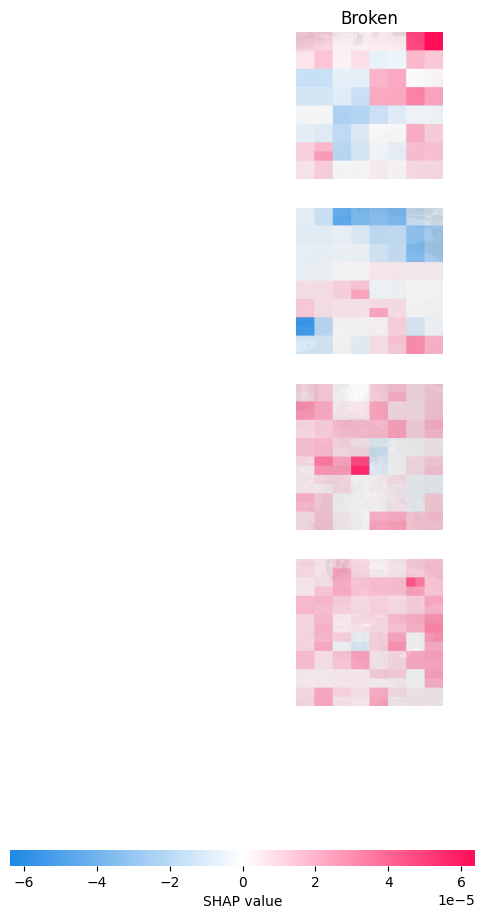

In [50]:
# Mostra cada imagem com o mapa de importância ao lado
shap.image_plot(shap_values)